# Italian Parkinson's Voice & Speech — Improved Research Pipeline

**Purpose:** Research prototype for Parkinson's disease (PD) vs healthy-control (HC) classification from voice recordings.

This revised notebook focuses on methodological reliability, participant-level separation, caching, and transparent dataset auditing. It does **not** promise a particular accuracy.

## Important corrections versus the first notebook
- Participant identity is audited before modeling; no missing participants are silently invented.
- Participant-wise train/validation/test separation prevents recordings from the same participant crossing splits.
- Classical models are selected using grouped cross-validation on training participants only. The held-out test set is used once for final evaluation.
- CNN validation participants are separated from CNN training participants.
- Feature and Log-Mel extraction are cached to avoid repeating expensive audio processing.
- Recording-level and participant-level results are both reported.

**Dataset limitation:** The previous run found 831 WAV files but only 61 unique participant folders (15 young HC, 22 elderly HC, 24 PD). The expected folder labels suggest 65 participants (15 + 22 + 28). This notebook audits the discrepancy; it does not assume the four missing PD participants exist in the audio data.

**Validation note:** This is a research workflow, not a clinically validated diagnostic system. The actual dataset folder structure and participant counts must be checked from the audit outputs. No accuracy target is guaranteed.


## 0. Install dependencies

In [1]:
!pip -q install librosa soundfile scikit-learn imbalanced-learn seaborn joblib tqdm

## 1. Mount Drive and configure paths

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# Change this only if your folder has a different name.
DATASET_ROOT = Path('/content/drive/MyDrive/Italian_Parkinson_Dataset')
OUTPUT_DIR = DATASET_ROOT / 'parkinsons_results_v2'
CACHE_DIR = Path('/content/parkinsons_cache')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

assert DATASET_ROOT.exists(), f'Dataset folder not found: {DATASET_ROOT}'
print('Dataset:', DATASET_ROOT)
print('Output:', OUTPUT_DIR)

Mounted at /content/drive
Dataset: /content/drive/MyDrive/Italian_Parkinson_Dataset
Output: /content/drive/MyDrive/Italian_Parkinson_Dataset/parkinsons_results_v2


## 2. Imports and reproducibility

In [3]:
import os, re, json, math, random, hashlib, warnings, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import Audio, display

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, StratifiedShuffleSplit, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
import joblib

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings('ignore')
print('Versions:', {'numpy': np.__version__, 'pandas': pd.__version__, 'librosa': librosa.__version__})

Versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'librosa': '0.11.0'}


## 3. Detect cohorts

The folder names are matched flexibly. Each cohort folder should contain participant subfolders, and those participant folders should contain WAV files (possibly in nested task folders).

In [4]:

# SECTION 3: Detect cohort folders (FIXED)

GROUP_RULES = {
    'young_hc': [
        r'^15\s*young\s*healthy\s*control$',
        r'^young.*healthy'
    ],
    'elderly_hc': [
        r'^22\s*elderly\s*healthy\s*control$',
        r'^elderly.*healthy'
    ],
    'pd': [
        r'^28\s*people\s*with\s*parkinson',
        r'^people.*parkinson'
    ]
}

# Ignore output, cache and other generated folders
top_dirs = [
    p for p in DATASET_ROOT.iterdir()
    if p.is_dir()
    and 'result' not in p.name.lower()
    and 'cache' not in p.name.lower()
]

group_dirs = {}

for group, patterns in GROUP_RULES.items():
    matches = [
        d for d in top_dirs
        if any(re.search(pattern, d.name.strip(), re.I)
               for pattern in patterns)
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one folder for {group}; "
            f"found {[m.name for m in matches]}"
        )

    group_dirs[group] = matches[0]

print("Successfully detected dataset folders:")

for group, folder in group_dirs.items():
    print(f"{group}: {folder.name}")


Successfully detected dataset folders:
young_hc: 15 Young Healthy Control
elderly_hc: 22 Elderly Healthy Control
pd: 28 People with Parkinson's disease


## 4. Scan recordings and audit participant-folder structure

Healthy cohorts store participant folders directly under their cohort root. The Parkinson's cohort has an extra range-folder level (`1-5`, `6-10`, `11-16`, `17-28`), and the individual participant folders are inside those ranges. The scanner below handles both layouts and keeps the range in the Parkinson's participant ID to avoid accidental name collisions.

In [5]:
TASK_CODES = sorted([
    'FB1','FB2','VA1','VA2','VE1','VE2','VI1','VI2',
    'VO1','VO2','VU1','VU2','PR1','B1','B2','D1','D2'
], key=len, reverse=True)

PD_RANGE_FOLDERS = {'1-5', '6-10', '11-16', '17-28'}

def parse_task(filename):
    stem = Path(filename).stem.upper()
    for task in TASK_CODES:
        if stem.startswith(task):
            return task
    return 'UNKNOWN'

def participant_from_path(wav_path, cohort, cohort_root):
    """Return (participant_id, participant_folder, range_folder).

    HC layout: cohort_root / participant_folder / recording.wav
    PD layout: cohort_root / range_folder / participant_folder / recording.wav
    """
    rel = Path(wav_path).relative_to(cohort_root)
    if cohort == 'pd':
        if len(rel.parts) < 3:
            return None, None, None
        range_folder, person_folder = rel.parts[0], rel.parts[1]
        if range_folder not in PD_RANGE_FOLDERS:
            return None, None, None
        # Include range in the ID so repeated folder names cannot merge people.
        return f'{range_folder}::{person_folder}', person_folder, range_folder
    if len(rel.parts) < 2:
        return None, None, None
    person_folder = rel.parts[0]
    return person_folder, person_folder, None

records = []
directory_audit = []
for cohort, root in group_dirs.items():
    wavs = [p for p in root.rglob('*') if p.is_file() and p.suffix.lower() == '.wav']
    by_participant = Counter()
    for wav in wavs:
        participant_id, pid_folder, range_folder = participant_from_path(wav, cohort, root)
        if participant_id is None:
            continue
        by_participant[participant_id] += 1
        records.append({
            'path': str(wav), 'filename': wav.name, 'task': parse_task(wav.name),
            'cohort': cohort, 'label': 1 if cohort == 'pd' else 0,
            'participant_folder': pid_folder,
            'range_folder': range_folder,
            'participant': f'{cohort}::{participant_id}',
            'size_kb': round(wav.stat().st_size / 1024, 1)
        })
    for participant_id, count in sorted(by_participant.items()):
        directory_audit.append({
            'cohort': cohort,
            'participant_id': participant_id,
            'participant_folder': participant_id.split('::')[-1] if cohort == 'pd' else participant_id,
            'range_folder': participant_id.split('::')[0] if cohort == 'pd' else None,
            'wav_count': count
        })

manifest = pd.DataFrame(records)
directory_audit = pd.DataFrame(directory_audit)
if manifest.empty:
    raise ValueError('No WAV files found. Check DATASET_ROOT and folder layout.')

print('WAV files:', len(manifest))
print('Participant counts by cohort:')
cohort_counts = manifest.groupby('cohort').agg(
    wav_files=('path','count'), participants=('participant','nunique')
).reset_index()
display(cohort_counts)
print('Participant-folder audit:')
display(directory_audit.groupby('cohort').agg(
    participant_folders=('participant_id','nunique'),
    folders_with_audio=('wav_count','count'),
    min_wavs=('wav_count','min'), median_wavs=('wav_count','median'),
    max_wavs=('wav_count','max')
).reset_index())
print('Parkinson range-folder counts:')
if 'range_folder' in directory_audit.columns:
    display(directory_audit[directory_audit.cohort == 'pd'].groupby('range_folder').agg(
        participants=('participant_id','nunique'), recordings=('wav_count','sum')
    ).reset_index())
print('Unique participants:', manifest.participant.nunique())
print('Unknown task files:', int((manifest.task == 'UNKNOWN').sum()))
display(directory_audit.head(40))

manifest.to_csv(OUTPUT_DIR / 'audio_manifest_audited.csv', index=False)
directory_audit.to_csv(OUTPUT_DIR / 'participant_folder_audit.csv', index=False)

WAV files: 831
Participant counts by cohort:


,cohort,wav_files,participants
0,elderly_hc,349,22
1,pd,437,28
2,young_hc,45,15


Participant-folder audit:


,cohort,participant_folders,folders_with_audio,min_wavs,median_wavs,max_wavs
0,elderly_hc,22,22,13,16.0,16
1,pd,28,28,10,16.0,16
2,young_hc,15,15,3,3.0,3


Parkinson range-folder counts:


,range_folder,participants,recordings
0,1-5,5,80
1,11-16,6,96
2,17-28,12,181
3,6-10,5,80


Unique participants: 65
Unknown task files: 0


,cohort,participant_id,participant_folder,range_folder,wav_count
0,young_hc,Alberto R,Alberto R,None,3
1,young_hc,Alessandro M,Alessandro M,None,3
2,young_hc,Alessandro P,Alessandro P,None,3
3,young_hc,Arianna P,Arianna P,None,3
4,young_hc,Biagio P,Biagio P,None,3
5,young_hc,Daniele R,Daniele R,None,3
6,young_hc,Davide M,Davide M,None,3
7,young_hc,Davide S,Davide S,None,3
8,young_hc,Domenico T,Domenico T,None,3
9,young_hc,Gennaro T,Gennaro T,None,3


## 5. Verify participant counts before modeling

The Parkinson's directory contains four **range folders**, not four participants. The scan now descends one additional level for Parkinson's and identifies the individual person folders. The expected cohort counts are 15 young healthy, 22 elderly healthy, and 28 Parkinson's participants. A mismatch is flagged for investigation; the notebook never fabricates missing participants.

In [6]:
EXPECTED_PARTICIPANTS = {'young_hc': 15, 'elderly_hc': 22, 'pd': 28}
observed = manifest.groupby('cohort').participant.nunique().to_dict()
all_counts_match = True
for cohort, expected in EXPECTED_PARTICIPANTS.items():
    got = int(observed.get(cohort, 0))
    status = 'OK' if got == expected else 'CHECK'
    all_counts_match &= (got == expected)
    print(f'{cohort}: observed={got}, expected_from_folder_label={expected} -> {status}')

if not all_counts_match:
    print('WARNING: Participant counts do not match the folder labels. Inspect participant_folder_audit.csv before interpreting model results.')
else:
    print('All three cohort participant counts match the dataset folder labels.')

young_hc: observed=15, expected_from_folder_label=15 -> OK
elderly_hc: observed=22, expected_from_folder_label=22 -> OK
pd: observed=28, expected_from_folder_label=28 -> OK
All three cohort participant counts match the dataset folder labels.


## 6. Optional: listen to a sample recording

In [7]:
sample_row = manifest.sample(1, random_state=SEED).iloc[0]
print(sample_row[['cohort','participant_folder','task','filename']])
audio, sr = sf.read(sample_row.path)
display(Audio(audio.T if audio.ndim == 2 else audio, rate=sr))

cohort                                          pd
participant_folder                         Lucia R
task                                           PR1
filename              PR1rlouscsi77F2605161834.wav
Name: 610, dtype: object


## 7. Handcrafted feature extraction with cache

Features: MFCC mean/std, delta-MFCC mean/std, spectral centroid, bandwidth, rolloff, zero-crossing rate, RMS, chroma, and duration.

The cache stores one row per recording. On later runs, existing cached features are reused by file path + file size + modification time. If the audio file changes, its cache key changes.

In [8]:
TARGET_SR = 16000
N_MFCC = 20
FEATURE_CACHE = CACHE_DIR / 'handcrafted_features.csv'

def file_cache_key(path):
    p = Path(path)
    stat = p.stat()
    raw = f'{str(p)}|{stat.st_size}|{stat.st_mtime_ns}'
    return hashlib.sha1(raw.encode()).hexdigest()

def mean_std_features(arr, prefix, out):
    arr = np.asarray(arr)
    if arr.ndim == 1:
        out[f'{prefix}_mean'] = float(np.mean(arr))
        out[f'{prefix}_std'] = float(np.std(arr))
    else:
        for j in range(arr.shape[0]):
            out[f'{prefix}_{j+1}_mean'] = float(np.mean(arr[j]))
            out[f'{prefix}_{j+1}_std'] = float(np.std(arr[j]))

def extract_features(path):
    y, sr = sf.read(path, dtype='float32')
    if y.ndim == 2:
        y = y.mean(axis=1)
    if y.size == 0:
        raise ValueError('Empty audio')
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)
        sr = TARGET_SR
    y = y - np.mean(y)
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / (peak + 1e-9)

    out = {'duration_sec': float(len(y) / sr)}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    delta = librosa.feature.delta(mfcc, mode='nearest')
    mean_std_features(mfcc, 'mfcc', out)
    mean_std_features(delta, 'delta_mfcc', out)

    for name, arr in {
        'spectral_centroid': librosa.feature.spectral_centroid(y=y, sr=sr),
        'spectral_bandwidth': librosa.feature.spectral_bandwidth(y=y, sr=sr),
        'spectral_rolloff': librosa.feature.spectral_rolloff(y=y, sr=sr),
        'zcr': librosa.feature.zero_crossing_rate(y),
        'rms': librosa.feature.rms(y=y),
        'chroma': librosa.feature.chroma_stft(y=y, sr=sr)
    }.items():
        mean_std_features(arr, name, out)
    return out

# Reuse cached rows where the file fingerprint matches.
manifest = manifest.copy()
manifest['cache_key'] = manifest.path.map(file_cache_key)
if FEATURE_CACHE.exists():
    cached = pd.read_csv(FEATURE_CACHE)
    cache_map = {r['cache_key']: r for r in cached.to_dict('records')}
else:
    cache_map = {}

feature_rows, errors = [], []
to_process = manifest[~manifest.cache_key.isin(cache_map)]
print(f'Total recordings: {len(manifest)} | Cached: {len(manifest)-len(to_process)} | To process: {len(to_process)}')

for row in tqdm(to_process.itertuples(index=False), total=len(to_process), desc='Extracting features'):
    try:
        feats = extract_features(row.path)
        feats.update({
            'cache_key': row.cache_key, 'path': row.path, 'filename': row.filename,
            'task': row.task, 'cohort': row.cohort, 'label': row.label,
            'participant': row.participant, 'participant_folder': row.participant_folder
        })
        cache_map[row.cache_key] = feats
    except Exception as e:
        errors.append({'path': row.path, 'error': repr(e)})

features_df = pd.DataFrame(list(cache_map.values()))
features_df = features_df[features_df.cache_key.isin(set(manifest.cache_key))].copy()
feature_errors = pd.DataFrame(errors, columns=['path','error'])
features_df.to_csv(FEATURE_CACHE, index=False)
features_df.to_csv(OUTPUT_DIR / 'recording_features.csv', index=False)
feature_errors.to_csv(OUTPUT_DIR / 'feature_errors.csv', index=False)

print('Feature rows:', len(features_df), '| Errors this run:', len(feature_errors))
print('Cached feature file:', FEATURE_CACHE)
display(features_df.head())

Total recordings: 831 | Cached: 0 | To process: 831


Extracting features:   0%|          | 0/831 [00:00<?, ?it/s]

Feature rows: 831 | Errors this run: 0
Cached feature file: /content/parkinsons_cache/handcrafted_features.csv


,duration_sec,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,...,chroma_12_mean,chroma_12_std,cache_key,path,filename,task,cohort,label,participant,participant_folder
0,46.497937,-197.212296,70.930038,76.056320,38.265583,19.664696,20.858248,24.487020,22.520317,-1.662301,...,0.353952,0.305266,fd73bcb83bd85faf4579c0c0553ebba5d55412dd,/content/drive/MyDrive/Italian_Parkinson_Datas...,B2LBULCAAS94M100120171023.wav,B2,young_hc,0,young_hc::Nicolas M,Nicolas M
1,53.394312,-230.201248,74.418503,71.158760,33.861828,18.682657,20.260607,22.443447,22.418621,-0.471397,...,0.290337,0.224813,eaf46a802ae36cd2c0e7d782c87583d3e31ca464,/content/drive/MyDrive/Italian_Parkinson_Datas...,PR1LBULCAAS94M100120171023.wav,PR1,young_hc,0,young_hc::Nicolas M,Nicolas M
2,45.296312,-192.067383,67.682655,79.943771,37.446629,20.119226,20.451778,25.575615,22.574146,-2.684630,...,0.376804,0.301087,e2436e62afb1fbc6c15d5171252b11a3b277777b,/content/drive/MyDrive/Italian_Parkinson_Datas...,B1LBULCAAS94M100120171023.wav,B1,young_hc,0,young_hc::Nicolas M,Nicolas M
3,46.289000,-162.055649,48.268555,83.438774,31.997318,28.891228,16.912149,21.589973,18.730873,-1.815223,...,0.467368,0.322528,27d10a5e731bb180be2c616bb96a31429cfb99a6,/content/drive/MyDrive/Italian_Parkinson_Datas...,B1LBULCAAS94M100120171063.wav,B1,young_hc,0,young_hc::Luca S,Luca S
4,37.590187,-135.719803,48.144600,79.529579,30.174679,28.634811,16.550964,23.941193,19.215508,1.100550,...,0.418009,0.286418,ca8cd58af42b0b2a84dc0c5e7acec4fc6d3c2ae5,/content/drive/MyDrive/Italian_Parkinson_Datas...,PR1LBULCAAS94M100120171063.wav,PR1,young_hc,0,young_hc::Luca S,Luca S


## 8. Verify feature table and labels

We require one feature row per successfully processed recording. The cohort label is the target; participant ID is used only for grouping, never as a predictor.

In [9]:
meta_cols = {'cache_key','path','filename','task','cohort','label','participant','participant_folder'}
feature_cols = [c for c in features_df.columns if c not in meta_cols]
features_df = features_df.replace([np.inf, -np.inf], np.nan)
features_df = features_df.dropna(subset=['label','participant'])
print('Rows:', len(features_df), 'Participants:', features_df.participant.nunique(),
      'Feature columns:', len(feature_cols))
print('Class counts (recordings):')
display(features_df.label.value_counts().rename(index={0:'HC',1:'PD'}).to_frame('recordings'))
print('Class counts (participants):')
display(features_df[['participant','label']].drop_duplicates().label.value_counts().rename(index={0:'HC',1:'PD'}).to_frame('participants'))
assert features_df.participant.notna().all()
assert features_df.groupby('participant').label.nunique().max() == 1, 'A participant has inconsistent labels'

Rows: 831 Participants: 65 Feature columns: 115
Class counts (recordings):


,recordings
label,
PD,437
HC,394


Class counts (participants):


,participants
label,
HC,37
PD,28


## 9. Participant-stratified train/test split

The split is stratified at the participant level: one row per participant determines class balance, then every recording from that participant is assigned to the same split. The held-out test participants are not used for model selection or threshold tuning.

In [10]:

# Participant-level stratified train/test split (no participant leakage)

X = features_df[feature_cols].copy()
y = features_df['label'].astype(int).copy()
groups = features_df['participant'].astype(str).copy()

# One row per participant is used to stratify the split.
participant_table_all = (
    features_df[['participant', 'label']]
    .drop_duplicates()
    .reset_index(drop=True)
)

assert participant_table_all.groupby('participant')['label'].nunique().max() == 1

participant_splitter = StratifiedShuffleSplit(
    n_splits=1, test_size=0.25, random_state=SEED
)

participant_train_pos, participant_test_pos = next(
    participant_splitter.split(
        participant_table_all['participant'],
        participant_table_all['label']
    )
)

train_people = set(participant_table_all.iloc[participant_train_pos]['participant'])
test_people = set(participant_table_all.iloc[participant_test_pos]['participant'])

train_idx = np.flatnonzero(groups.isin(train_people).to_numpy())
test_idx = np.flatnonzero(groups.isin(test_people).to_numpy())

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx].copy(), groups.iloc[test_idx].copy()
train_meta, test_meta = features_df.iloc[train_idx].copy(), features_df.iloc[test_idx].copy()

assert set(groups_train).isdisjoint(set(groups_test))
assert y_train.nunique() == 2 and y_test.nunique() == 2

print('Participant-wise stratified split successful')
print('Train recordings:', len(train_idx), '| Test recordings:', len(test_idx))
print('Train participants:', len(train_people), '| Test participants:', len(test_people))
print('Train participant class counts:')
display(participant_table_all[participant_table_all.participant.isin(train_people)].label.value_counts().rename(index={0:'HC',1:'PD'}))
print('Test participant class counts:')
display(participant_table_all[participant_table_all.participant.isin(test_people)].label.value_counts().rename(index={0:'HC',1:'PD'}))


Participant-wise stratified split successful
Train recordings: 605 | Test recordings: 226
Train participants: 48 | Test participants: 17
Train participant class counts:


,count
label,
HC,27
PD,21


Test participant class counts:


,count
label,
HC,10
PD,7


## 10. Classical ML: participant-stratified cross-validation on training participants only

Cross-validation is stratified using one row per participant. All recordings from a participant remain together in one fold. Model selection uses training participants only; the held-out test participants remain untouched.

In [11]:

# Classical ML: participant-stratified cross-validation on training participants only

models = {
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED))
    ]),
    'SVM RBF': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=SEED))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                         class_weight='balanced', random_state=SEED, n_jobs=-1))
    ]),
    'Extra Trees': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2,
                                       class_weight='balanced', random_state=SEED, n_jobs=-1))
    ])
}

# One row per training participant; stratify participants, then map each fold
# back to all recordings belonging to those participants.
participant_table_train = (
    pd.DataFrame({'participant': groups_train.to_numpy(), 'label': y_train.to_numpy()})
    .drop_duplicates()
    .reset_index(drop=True)
)

class_counts = participant_table_train['label'].value_counts()
n_splits = min(5, int(class_counts.min()))
if n_splits < 2:
    raise ValueError(
        f'Insufficient training participants per class for CV: {class_counts.to_dict()}'
    )

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
cv_rows = []

for name, model in models.items():
    fold_scores = []
    for fold, (p_tr, p_va) in enumerate(
        cv.split(participant_table_train['participant'], participant_table_train['label']), 1
    ):
        fold_train_people = set(participant_table_train.iloc[p_tr]['participant'])
        fold_val_people = set(participant_table_train.iloc[p_va]['participant'])

        tr = np.flatnonzero(groups_train.isin(fold_train_people).to_numpy())
        va = np.flatnonzero(groups_train.isin(fold_val_people).to_numpy())

        assert set(groups_train.iloc[tr]).isdisjoint(set(groups_train.iloc[va]))
        assert y_train.iloc[tr].nunique() == 2
        assert y_train.iloc[va].nunique() == 2

        fitted = clone(model)
        fitted.fit(X_train.iloc[tr], y_train.iloc[tr])
        pred = fitted.predict(X_train.iloc[va])

        score = balanced_accuracy_score(y_train.iloc[va], pred)
        fold_scores.append(float(score))
        print(f'{name} | Fold {fold}: balanced accuracy = {score:.4f}')

    cv_rows.append({
        'model': name,
        'cv_balanced_accuracy_mean': float(np.mean(fold_scores)),
        'cv_balanced_accuracy_std': float(np.std(fold_scores)),
        'fold_scores': fold_scores
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    'cv_balanced_accuracy_mean', ascending=False
)
display(cv_results)

best_name = cv_results.iloc[0]['model']
best_model = clone(models[best_name])
best_model.fit(X_train, y_train)

print('Selected model:', best_name)
print('Selection based only on training-participant cross-validation.')


Logistic Regression | Fold 1: balanced accuracy = 0.9121
Logistic Regression | Fold 2: balanced accuracy = 0.9112
Logistic Regression | Fold 3: balanced accuracy = 0.9812
Logistic Regression | Fold 4: balanced accuracy = 0.9041
Logistic Regression | Fold 5: balanced accuracy = 0.9552
SVM RBF | Fold 1: balanced accuracy = 0.8887
SVM RBF | Fold 2: balanced accuracy = 0.9746
SVM RBF | Fold 3: balanced accuracy = 0.9816
SVM RBF | Fold 4: balanced accuracy = 0.9804
SVM RBF | Fold 5: balanced accuracy = 0.9776
Random Forest | Fold 1: balanced accuracy = 0.8546
Random Forest | Fold 2: balanced accuracy = 0.9756
Random Forest | Fold 3: balanced accuracy = 0.9756
Random Forest | Fold 4: balanced accuracy = 0.9706
Random Forest | Fold 5: balanced accuracy = 0.9254
Extra Trees | Fold 1: balanced accuracy = 0.8555
Extra Trees | Fold 2: balanced accuracy = 0.9746
Extra Trees | Fold 3: balanced accuracy = 0.9756
Extra Trees | Fold 4: balanced accuracy = 0.9824
Extra Trees | Fold 5: balanced accuracy

,model,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,fold_scores
1,SVM RBF,0.960582,0.036017,"[0.8887061403508771, 0.9746436403508771, 0.981..."
3,Extra Trees,0.948331,0.047399,"[0.8555372807017544, 0.9746436403508771, 0.975..."
2,Random Forest,0.940350,0.046865,"[0.854577850877193, 0.9756030701754386, 0.9756..."
0,Logistic Regression,0.932781,0.030224,"[0.9121436403508771, 0.9111842105263157, 0.981..."


Selected model: SVM RBF
Selection based only on training-participant cross-validation.


## 11. Final classical model evaluation on untouched test participants

The test set is evaluated only after model selection is complete. Report recording-level and participant-level results separately.

                 precision    recall  f1-score   support

Healthy Control       0.97      0.94      0.96       121
     Parkinsons       0.94      0.97      0.95       105

       accuracy                           0.96       226
      macro avg       0.96      0.96      0.96       226
   weighted avg       0.96      0.96      0.96       226

Recording-level metrics:


,level,n,accuracy,balanced_accuracy,precision_pd,recall_pd,f1_pd,roc_auc
0,recording,226,0.955752,0.956789,0.93578,0.971429,0.953271,0.993861


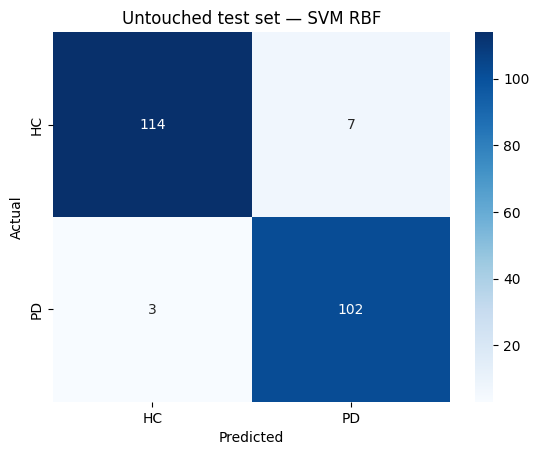

In [12]:
test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)[:, 1]

def metric_row(y_true, y_pred, y_prob=None, level='recording'):
    row = {
        'level': level, 'n': int(len(y_true)),
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_pd': precision_score(y_true, y_pred, zero_division=0),
        'recall_pd': recall_score(y_true, y_pred, zero_division=0),
        'f1_pd': f1_score(y_true, y_pred, zero_division=0)
    }
    row['roc_auc'] = roc_auc_score(y_true, y_prob) if y_prob is not None and len(np.unique(y_true)) == 2 else np.nan
    return row

recording_metrics = metric_row(y_test, test_pred, test_prob, 'recording')
print(classification_report(y_test, test_pred, target_names=['Healthy Control','Parkinsons'], zero_division=0))
print('Recording-level metrics:')
display(pd.DataFrame([recording_metrics]))
cm = confusion_matrix(y_test, test_pred, labels=[0,1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['HC','PD'], yticklabels=['HC','PD'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Untouched test set — {best_name}')
plt.show()

## 12. Participant-level evaluation

Average the PD probabilities across each held-out participant's recordings. This is the primary participant-level view, but the test cohort is small; show the participant count beside all metrics.

In [13]:
recording_test = test_meta[['participant','cohort','label','task','filename']].copy()
recording_test['prob_pd'] = test_prob
recording_test['pred'] = test_pred

participant_test = recording_test.groupby('participant').agg(
    cohort=('cohort','first'), label=('label','first'),
    mean_prob_pd=('prob_pd','mean'), n_recordings=('prob_pd','size')
).reset_index()
participant_test['pred'] = (participant_test.mean_prob_pd >= 0.5).astype(int)

participant_metrics = metric_row(participant_test.label, participant_test.pred,
                                 participant_test.mean_prob_pd, 'participant')
display(participant_test.sort_values('mean_prob_pd'))
display(pd.DataFrame([participant_metrics]))

,participant,cohort,label,mean_prob_pd,n_recordings,pred
15,young_hc::Daniele R,young_hc,0,0.000645,3,0
5,elderly_hc::PORCELLI A,elderly_hc,0,0.009845,16,0
3,elderly_hc::LUIGI P,elderly_hc,0,0.021473,16,0
4,elderly_hc::MARIACRISTINA P,elderly_hc,0,0.021597,16,0
6,elderly_hc::TERESA M,elderly_hc,0,0.024748,16,0
2,elderly_hc::GIOVANNI B,elderly_hc,0,0.057923,16,0
1,elderly_hc::GIOVANNA G,elderly_hc,0,0.072281,16,0
0,elderly_hc::ANTONIO C,elderly_hc,0,0.108423,16,0
16,young_hc::Davide M,young_hc,0,0.338763,3,0
14,young_hc::Alessandro M,young_hc,0,0.605406,3,1


,level,n,accuracy,balanced_accuracy,precision_pd,recall_pd,f1_pd,roc_auc
0,participant,17,0.941176,0.95,0.875,1.0,0.933333,1.0


## 13. CNN: participant-stratified train/validation/test partitions

The held-out test participants remain untouched. The training participants are split into CNN training and validation participants using stratification at participant level. Every recording from a participant stays in that participant's split.

In [14]:

# CNN train/validation split: stratify participants, then include all their recordings.
participant_table_train = (
    pd.DataFrame({'participant': groups_train.to_numpy(), 'label': y_train.to_numpy()})
    .drop_duplicates()
    .reset_index(drop=True)
)

cnn_splitter = StratifiedShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED + 1
)
cnn_train_pos, cnn_val_pos = next(
    cnn_splitter.split(
        participant_table_train['participant'],
        participant_table_train['label']
    )
)

cnn_train_people = set(participant_table_train.iloc[cnn_train_pos]['participant'])
cnn_val_people = set(participant_table_train.iloc[cnn_val_pos]['participant'])

cnn_train_idx = np.flatnonzero(groups_train.isin(cnn_train_people).to_numpy())
cnn_val_idx = np.flatnonzero(groups_train.isin(cnn_val_people).to_numpy())

cnn_train_meta = train_meta.iloc[cnn_train_idx].copy()
cnn_val_meta = train_meta.iloc[cnn_val_idx].copy()

assert set(cnn_train_meta.participant).isdisjoint(set(cnn_val_meta.participant))
assert set(cnn_train_meta.participant).isdisjoint(set(test_meta.participant))
assert set(cnn_val_meta.participant).isdisjoint(set(test_meta.participant))
assert cnn_train_meta.label.nunique() == 2 and cnn_val_meta.label.nunique() == 2

print('CNN train participants:', cnn_train_meta.participant.nunique())
print('CNN validation participants:', cnn_val_meta.participant.nunique())
print('CNN test participants:', test_meta.participant.nunique())
print('CNN train recordings:', len(cnn_train_meta))
print('CNN validation recordings:', len(cnn_val_meta))


CNN train participants: 38
CNN validation participants: 10
CNN test participants: 17
CNN train recordings: 474
CNN validation recordings: 131


## 14. Log-Mel spectrogram extraction with cache

This step reads audio again, but cached `.npy` spectrograms prevent repeated work in later runs. The baseline uses a fixed 5-second window from the beginning of each recording; this limitation must be stated in the report.

In [15]:
import tensorflow as tf
tf.random.set_seed(SEED)

TARGET_SR = 16000
DURATION = 5.0
N_MELS = 64
N_FFT = 1024
HOP = 256
MAX_SAMPLES = int(TARGET_SR * DURATION)
LOGMEL_CACHE = CACHE_DIR / 'logmel'
LOGMEL_CACHE.mkdir(exist_ok=True)

def logmel_cache_path(audio_path):
    return LOGMEL_CACHE / (file_cache_key(audio_path) + '.npy')

def wav_to_logmel(audio_path):
    cache_path = logmel_cache_path(audio_path)
    if cache_path.exists():
        return np.load(cache_path)
    y, sr = sf.read(audio_path, dtype='float32')
    if y.ndim == 2:
        y = y.mean(axis=1)
    if y.size == 0:
        raise ValueError('Empty audio')
    if sr != TARGET_SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=TARGET_SR)
    if len(y) < MAX_SAMPLES:
        y = np.pad(y, (0, MAX_SAMPLES - len(y)))
    else:
        y = y[:MAX_SAMPLES]
    mel = librosa.feature.melspectrogram(y=y, sr=TARGET_SR, n_fft=N_FFT,
                                         hop_length=HOP, n_mels=N_MELS, power=2.0)
    logmel = librosa.power_to_db(mel, ref=np.max).astype(np.float32)
    np.save(cache_path, logmel)
    return logmel

def make_logmel_array(meta, name):
    arr, bad = [], []
    for row in tqdm(meta.itertuples(index=False), total=len(meta), desc=name):
        try:
            arr.append(wav_to_logmel(row.path))
        except Exception as e:
            bad.append({'path': row.path, 'error': repr(e)})
    if bad:
        raise RuntimeError(f'{len(bad)} files failed during {name}. See errors: {bad[:5]}')
    return np.stack(arr)[..., None]

X_cnn_train = make_logmel_array(cnn_train_meta, 'CNN train')
X_cnn_val = make_logmel_array(cnn_val_meta, 'CNN validation')
X_cnn_test = make_logmel_array(test_meta, 'CNN test')

y_cnn_train = cnn_train_meta.label.to_numpy().astype('float32')
y_cnn_val = cnn_val_meta.label.to_numpy().astype('float32')
y_cnn_test = test_meta.label.to_numpy().astype('float32')
print('Shapes:', X_cnn_train.shape, X_cnn_val.shape, X_cnn_test.shape)

CNN train:   0%|          | 0/474 [00:00<?, ?it/s]

CNN validation:   0%|          | 0/131 [00:00<?, ?it/s]

CNN test:   0%|          | 0/226 [00:00<?, ?it/s]

Shapes: (474, 64, 313, 1) (131, 64, 313, 1) (226, 64, 313, 1)


## 15. Train CNN with group-wise validation and early stopping

In [16]:

# CNN training with participant-aware sample weights and group-wise validation

cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X_cnn_train.shape[1:]),
    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.45),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.35),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

# Give each participant equal total weight, then balance the two classes.
train_participant_counts = cnn_train_meta['participant'].value_counts()
n_train_participants = cnn_train_meta['participant'].nunique()
n_classes = cnn_train_meta['label'].nunique()

sample_weights = np.array([
    1.0 / train_participant_counts[pid]
    for pid in cnn_train_meta['participant']
], dtype=np.float32)

# Normalize weights so their mean is 1.0.
sample_weights *= len(sample_weights) / sample_weights.sum()

class_participant_counts = (
    cnn_train_meta[['participant', 'label']]
    .drop_duplicates()['label'].value_counts().to_dict()
)
class_weights_participant = {
    cls: n_train_participants / (n_classes * count)
    for cls, count in class_participant_counts.items()
}
sample_weights *= cnn_train_meta['label'].map(class_weights_participant).to_numpy()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=8, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
    )
]

history = cnn.fit(
    X_cnn_train, y_cnn_train,
    sample_weight=sample_weights,
    validation_data=(X_cnn_val, y_cnn_val),
    epochs=60,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / 'cnn_training_history.csv', index=False
)


Epoch 1/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 534ms/step - accuracy: 0.5844 - auc: 0.5882 - loss: 0.6678 - val_accuracy: 0.4885 - val_auc: 0.4464 - val_loss: 2.1205 - learning_rate: 3.0000e-04
Epoch 2/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 476ms/step - accuracy: 0.5886 - auc: 0.6195 - loss: 0.6298 - val_accuracy: 0.4885 - val_auc: 0.4826 - val_loss: 1.5937 - learning_rate: 3.0000e-04
Epoch 3/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 532ms/step - accuracy: 0.6139 - auc: 0.6720 - loss: 0.5737 - val_accuracy: 0.4885 - val_auc: 0.5194 - val_loss: 1.1182 - learning_rate: 3.0000e-04
Epoch 4/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 461ms/step - accuracy: 0.6772 - auc: 0.7338 - loss: 0.5572 - val_accuracy: 0.4885 - val_auc: 0.5526 - val_loss: 1.0577 - learning_rate: 3.0000e-04
Epoch 5/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 486ms/step - accuracy: 0.7131 - auc: 0.7698 - loss: 0.5090 - val_accuracy: 0.4962 - val_auc: 0.6325 - val_loss: 0.8999 - learning_rate: 3.0000e-04
Epoch 6/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 447ms/step - 

## 16. CNN evaluation on untouched test participants

No threshold tuning is performed on the test set. The default threshold is 0.5. If threshold tuning is later needed, use validation participants only.

In [17]:
cnn_prob = cnn.predict(X_cnn_test, verbose=0).ravel()
cnn_pred = (cnn_prob >= 0.5).astype(int)
print(classification_report(y_cnn_test, cnn_pred,
                            target_names=['Healthy Control','Parkinsons'], zero_division=0))
cnn_recording_metrics = metric_row(y_cnn_test, cnn_pred, cnn_prob, 'recording_CNN')
display(pd.DataFrame([cnn_recording_metrics]))

cnn_recording_test = test_meta[['participant','cohort','label','task','filename']].copy()
cnn_recording_test['prob_pd'] = cnn_prob
cnn_recording_test['pred'] = cnn_pred
cnn_participant_test = cnn_recording_test.groupby('participant').agg(
    cohort=('cohort','first'), label=('label','first'),
    mean_prob_pd=('prob_pd','mean'), n_recordings=('prob_pd','size')
).reset_index()
cnn_participant_test['pred'] = (cnn_participant_test.mean_prob_pd >= 0.5).astype(int)
cnn_participant_metrics = metric_row(cnn_participant_test.label, cnn_participant_test.pred,
                                     cnn_participant_test.mean_prob_pd, 'participant_CNN')
display(pd.DataFrame([cnn_participant_metrics]))

                 precision    recall  f1-score   support

Healthy Control       0.97      0.97      0.97       121
     Parkinsons       0.96      0.97      0.97       105

       accuracy                           0.97       226
      macro avg       0.97      0.97      0.97       226
   weighted avg       0.97      0.97      0.97       226



,level,n,accuracy,balanced_accuracy,precision_pd,recall_pd,f1_pd,roc_auc
0,recording_CNN,226,0.969027,0.969185,0.962264,0.971429,0.966825,0.989217


,level,n,accuracy,balanced_accuracy,precision_pd,recall_pd,f1_pd,roc_auc
0,participant_CNN,17,0.941176,0.95,0.875,1.0,0.933333,1.0


## 17. Explainability: permutation importance on held-out test data

Permutation importance is an exploratory estimate of how much the fitted model's test balanced accuracy changes when one feature is shuffled. It is not causal evidence. With a small test set, interpret rankings cautiously.

,feature,importance_mean,importance_std
19,mfcc_10_mean,0.007178,0.003976
11,mfcc_6_mean,0.006379,0.006002
94,chroma_2_std,0.005301,0.004422
21,mfcc_11_mean,0.004825,0.004638
1,mfcc_1_mean,0.004789,0.006142
2,mfcc_1_std,0.004762,0.005432
13,mfcc_7_mean,0.004699,0.003982
84,spectral_bandwidth_1_std,0.004412,0.003361
61,delta_mfcc_11_mean,0.004258,0.001865
9,mfcc_5_mean,0.003935,0.003347


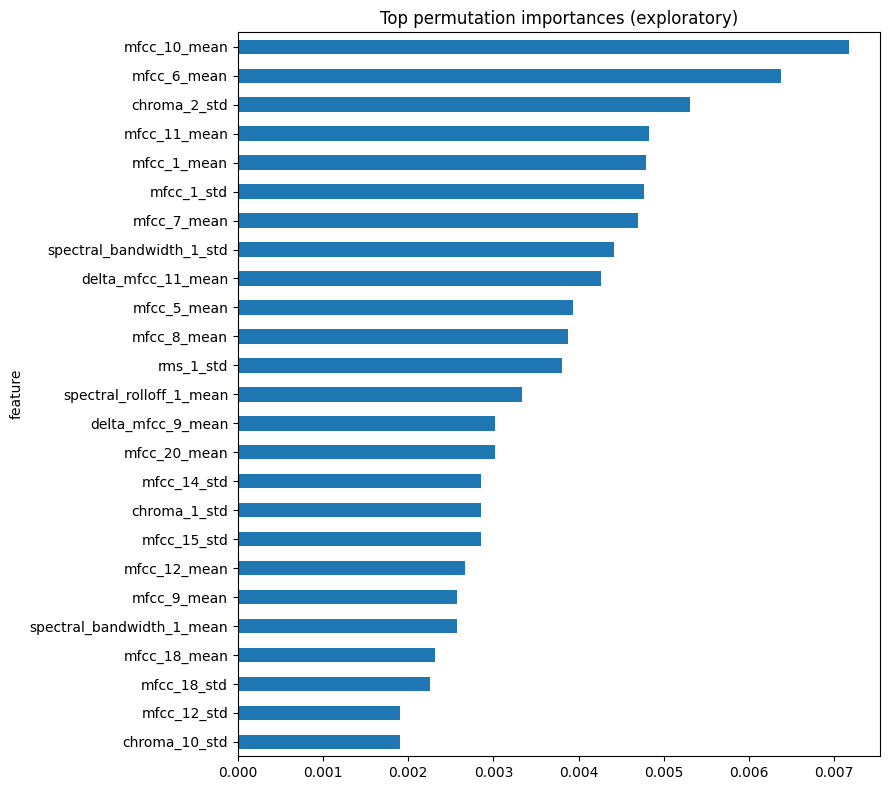

In [18]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=SEED,
    scoring='balanced_accuracy', n_jobs=-1
)
importance = pd.DataFrame({
    'feature': feature_cols,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std
}).sort_values('importance_mean', ascending=False)
display(importance.head(25))
importance.head(25).sort_values('importance_mean').plot(
    x='feature', y='importance_mean', kind='barh', figsize=(9,8), legend=False,
    title='Top permutation importances (exploratory)'
)
plt.tight_layout()
plt.show()

## 18. Task-wise descriptive evaluation

Task-wise results are descriptive only. A task with very few held-out participants should not be treated as a robust standalone model.

In [19]:
task_rows = []
for task, part in recording_test.groupby('task'):
    if part.label.nunique() < 2:
        continue
    task_rows.append({
        'task': task, 'test_recordings': len(part),
        'test_participants': part.participant.nunique(),
        'balanced_accuracy': balanced_accuracy_score(part.label, part.pred),
        'f1_pd': f1_score(part.label, part.pred, zero_division=0)
    })
task_results = pd.DataFrame(task_rows)
if not task_results.empty:
    display(task_results.sort_values('test_participants', ascending=False))

,task,test_recordings,test_participants,balanced_accuracy,f1_pd
0,B1,17,17,0.950000,0.933333
5,PR1,17,17,0.950000,0.933333
1,B2,15,15,0.950000,0.909091
2,D1,14,14,1.000000,1.000000
3,D2,14,14,1.000000,1.000000
4,FB1,14,14,1.000000,1.000000
6,VA1,14,14,0.928571,0.923077
8,VE1,14,14,1.000000,1.000000
14,VU1,14,14,1.000000,1.000000
10,VI1,14,14,0.928571,0.923077


## 19. Save all models, metrics, splits, and audit outputs

In [20]:
joblib.dump(best_model, OUTPUT_DIR / 'best_classical_model.joblib')
cnn.save(OUTPUT_DIR / 'logmel_cnn.keras')

cv_results.to_csv(OUTPUT_DIR / 'classical_group_cv_results.csv', index=False)
pd.DataFrame([recording_metrics, participant_metrics,
              cnn_recording_metrics, cnn_participant_metrics]).to_csv(
    OUTPUT_DIR / 'final_metrics.csv', index=False
)
recording_test.to_csv(OUTPUT_DIR / 'classical_recording_test_predictions.csv', index=False)
participant_test.to_csv(OUTPUT_DIR / 'classical_participant_test_predictions.csv', index=False)
cnn_recording_test.to_csv(OUTPUT_DIR / 'cnn_recording_test_predictions.csv', index=False)
cnn_participant_test.to_csv(OUTPUT_DIR / 'cnn_participant_test_predictions.csv', index=False)
importance.to_csv(OUTPUT_DIR / 'permutation_feature_importance.csv', index=False)
if not task_results.empty:
    task_results.to_csv(OUTPUT_DIR / 'task_wise_descriptive_results.csv', index=False)

split_audit = pd.DataFrame([
    {'split':'classical_train', 'participant_count':len(train_people), 'recording_count':len(train_idx)},
    {'split':'test', 'participant_count':len(test_people), 'recording_count':len(test_idx)},
    {'split':'cnn_train', 'participant_count':cnn_train_meta.participant.nunique(), 'recording_count':len(cnn_train_meta)},
    {'split':'cnn_validation', 'participant_count':cnn_val_meta.participant.nunique(), 'recording_count':len(cnn_val_meta)}
])
split_audit.to_csv(OUTPUT_DIR / 'participant_split_audit.csv', index=False)

summary = {
    'wav_files_scanned': int(len(manifest)),
    'feature_rows': int(len(features_df)),
    'feature_errors': int(len(feature_errors)),
    'participants_detected': int(features_df.participant.nunique()),
    'participants_by_cohort': {k:int(v) for k,v in features_df.groupby('cohort').participant.nunique().to_dict().items()},
    'train_participants': int(len(train_people)),
    'test_participants': int(len(test_people)),
    'classical_model_selected_by_training_group_cv': str(best_name),
    'classical_cv_balanced_accuracy_mean': float(cv_results.iloc[0].cv_balanced_accuracy_mean),
    'note': 'Research prototype only. Small participant sample; external validation is required. Not a clinical diagnostic tool.'
}
with open(OUTPUT_DIR / 'run_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print('All outputs saved to:', OUTPUT_DIR)

{
  "wav_files_scanned": 831,
  "feature_rows": 831,
  "feature_errors": 0,
  "participants_detected": 65,
  "participants_by_cohort": {
    "elderly_hc": 22,
    "pd": 28,
    "young_hc": 15
  },
  "train_participants": 48,
  "test_participants": 17,
  "classical_model_selected_by_training_group_cv": "SVM RBF",
  "classical_cv_balanced_accuracy_mean": 0.9605817511823573,
  "note": "Research prototype only. Small participant sample; external validation is required. Not a clinical diagnostic tool."
}
All outputs saved to: /content/drive/MyDrive/Italian_Parkinson_Dataset/parkinsons_results_v2


## 20. Final research reporting checklist

Before writing the report or presenting results:

1. Confirm the participant audit detects 15 young healthy, 22 elderly healthy, and 28 Parkinson's participants (if all expected recordings are present).
2. State the number of WAV files and actual detected participants by cohort.
3. Report participant-wise train/validation/test counts and confirm no participant overlap.
4. Report grouped cross-validation results separately from held-out test results.
5. Report recording-level and participant-level metrics separately.
6. Discuss the small participant sample, class imbalance, language/task effects, fixed 5-second CNN window, and need for external validation.
7. Do not claim clinical diagnostic performance or generalization to other populations.

**Important:** This notebook has been updated for the confirmed Parkinson's folder hierarchy, but rerun every cell from the beginning. Previous outputs and metrics have been cleared because they were generated using the incorrect participant grouping.